<center><h1>Liu_Yanchen_HW3</h1></center>
<br>
<br>

Name: Yanchen Liu
<br>
Github Username: jamesnulliu

## 1. Time Series Classification Part 1: Feature Creation/Extraction

We classify human activities from time series produced by a Wireless Sensor Network
(the **AReM** data set). Each instance is one person performing one activity for two
minutes; the network reports 6 time series of 480 samples each, taken at 4 Hz
(one sample every 250 ms):

| series | meaning |
| --- | --- |
| `avg_rss12`, `var_rss12` | mean / variance of the RSS between sensor pair 1-2 |
| `avg_rss13`, `var_rss13` | mean / variance of the RSS between sensor pair 1-3 |
| `avg_rss23`, `var_rss23` | mean / variance of the RSS between sensor pair 2-3 |

This homework covers **feature creation only** — turning each 6 x 480 instance into a
single row of time-domain features. The classifiers that consume these features are
built in Homework 4.

### (a) Download Data

Package imports

In [1]:
import itertools
import os
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# The two constant features found in 1(c)iii make f_classif divide by a zero
# within-group variance; the resulting NaN is handled explicitly below.
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)

# Blue / orange: colour-blind safe pair (same palette as HW1 and HW2)
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

RANDOM_STATE = 42

Get the AReM Data Set

The archive was downloaded from the UCI repository
([Activity Recognition system based on Multisensor data fusion](https://archive.ics.uci.edu/ml/datasets/Activity+Recognition+system+based+on+Multisensor+data+fusion+%28AReM%29))
and unpacked under `../data/`. All paths below are **relative** and use `/` separators.

Four of the 88 files are not machine-readable as distributed; the footnote in the
assignment refers to exactly this ("some of the data files need very minor cleaning").
The reader below repairs all four, so no file is edited by hand:

| file | defect | repair |
| --- | --- | --- |
| `bending2/dataset4.csv` | whitespace- instead of comma-delimited | split on any run of commas/whitespace |
| `cycling/dataset9.csv` | last row ends in a stray comma (8 fields) | empty fields dropped |
| `cycling/dataset14.csv` | last row ends in a stray comma (8 fields) | empty fields dropped |
| `sitting/dataset8.csv` | the sample at *t* = 13500 ms is missing (479 rows) | row restored by linear interpolation in time |

In [2]:
AREM_DIR = "../data/Homework 3, 4 Data/AReM"

ACTIVITIES = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]
SERIES = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
N_TIME = 480      # samples per time series
CLOCK_MS = 250    # sampling period in milliseconds


def read_instance(path):
    """Read one AReM dataset file, repairing the four known formatting defects."""
    rows = []
    with open(path, "r") as fh:
        for line in fh:
            line = line.strip()
            if not line or line.startswith("#"):          # drop the 5 header comments
                continue
            # Splitting on any run of commas/whitespace handles both the whitespace-
            # delimited file and the two rows that end in a stray comma.
            fields = [tok for tok in re.split(r"[,\s]+", line) if tok != ""]
            rows.append([float(tok) for tok in fields])

    df = pd.DataFrame(rows, columns=["time"] + SERIES)

    # Restore any missing sample so that every instance really is 480 points long.
    grid = np.arange(N_TIME) * CLOCK_MS
    if len(df) != N_TIME or not np.array_equal(df["time"].to_numpy(), grid):
        df = (df.set_index("time")
                .reindex(grid)
                .interpolate(method="index", limit_direction="both")
                .rename_axis("time")
                .reset_index())
    return df[SERIES]


def load_arem(root=AREM_DIR):
    """Load all 88 instances; return the series, their labels and the test-set mask."""
    instances, labels, is_test, names = [], [], [], []
    for activity in ACTIVITIES:
        folder = os.path.join(root, activity)
        files = sorted(os.listdir(folder), key=lambda f: int(re.search(r"\d+", f).group()))
        for fname in files:
            idx = int(re.search(r"\d+", fname).group())
            instances.append(read_instance(os.path.join(folder, fname)))
            labels.append(activity)
            # (b) test set: datasets 1-2 in bending1/bending2, datasets 1-3 elsewhere.
            is_test.append(idx <= (2 if activity.startswith("bending") else 3))
            names.append(f"{activity}/{fname}")
    return instances, np.array(labels), np.array(is_test), names


instances, labels, is_test, names = load_arem()

print(f"instances loaded : {len(instances)}")
print(f"shape of each    : {set(df.shape for df in instances)}")
print(f"missing values   : {sum(int(df.isna().sum().sum()) for df in instances)}")

instances loaded : 88
shape of each    : {(480, 6)}
missing values   : 0


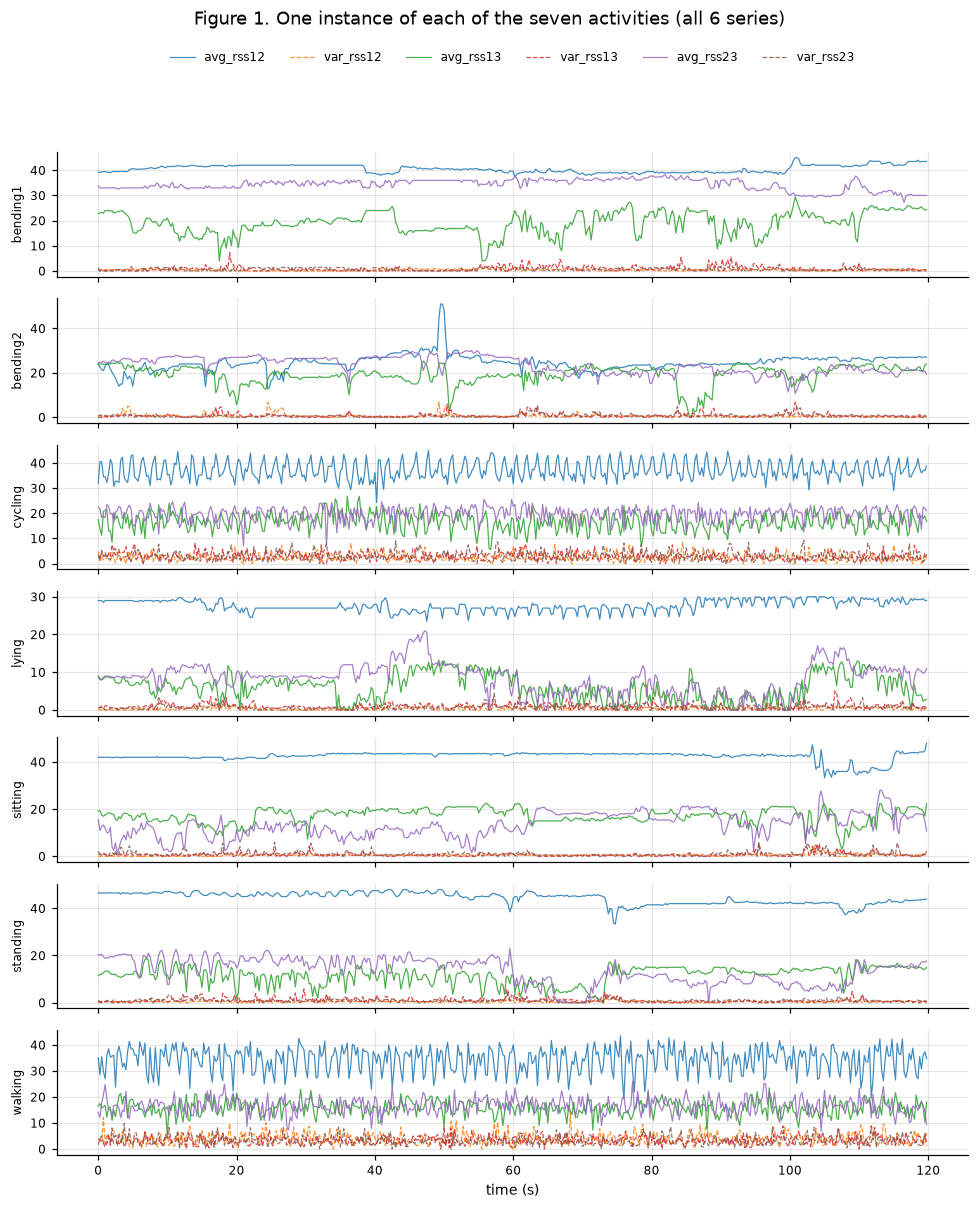

In [3]:
# A first look at one instance of each activity.
fig, axes = plt.subplots(7, 1, figsize=(9, 11), sharex=True)
t = np.arange(N_TIME) * CLOCK_MS / 1000.0
for ax, activity in zip(axes, ACTIVITIES):
    df = instances[list(labels).index(activity)]
    for s, style in zip(SERIES, ["-", "--", "-", "--", "-", "--"]):
        ax.plot(t, df[s], style, lw=0.8, alpha=0.85, label=s)
    ax.set_ylabel(activity, fontsize=8)
axes[0].legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, 1.9), frameon=False)
axes[-1].set_xlabel("time (s)")
fig.suptitle("Figure 1. One instance of each of the seven activities (all 6 series)", y=0.995)
fig.tight_layout()
plt.show()

**Figure 1** already shows why the problem is tractable. The two *bending* activities hold
`avg_rss13` very low and very flat, while the locomotion activities (cycling, walking) show
large, fast fluctuations in every channel. The static postures (lying, sitting, standing)
differ mostly in their mean levels. A handful of location and spread statistics should
therefore carry most of the signal, which is exactly what part (c) extracts.

### (b) Test and Train Data

As instructed: **datasets 1 and 2** of `bending1` and `bending2`, and **datasets 1, 2 and 3**
of the other five folders form the **test set**; everything else is the **train set**.

In [4]:
split = pd.DataFrame({"activity": labels, "split": np.where(is_test, "test", "train")})
counts = (split.groupby(["activity", "split"]).size().unstack(fill_value=0)
          .reindex(ACTIVITIES)[["train", "test"]])
counts["total"] = counts.sum(axis=1)
counts.loc["ALL"] = counts.sum()
print(counts.to_string())

train_idx = np.flatnonzero(~is_test)
test_idx = np.flatnonzero(is_test)
print(f"\ntrain instances: {len(train_idx)}   test instances: {len(test_idx)}")

split     train  test  total
activity                    
bending1      5     2      7
bending2      4     2      6
cycling      12     3     15
lying        12     3     15
sitting      12     3     15
standing     12     3     15
walking      12     3     15
ALL          69    19     88

train instances: 69   test instances: 19


69 training and 19 test instances, 88 in total — matching the count given in the assignment.

### (c) Feature Extraction

#### i. Research

Time-domain features for time series classification fall into a few families. The ones most
commonly used in the human-activity-recognition literature are:

**Location (central tendency)**
- mean, median, mode, trimmed mean

**Extremes and range**
- minimum, maximum, peak-to-peak range (max − min), crest factor (peak / RMS)

**Dispersion**
- variance, standard deviation, interquartile range (Q3 − Q1), mean absolute deviation,
  median absolute deviation, root mean square (RMS)

**Distribution shape**
- quantiles / percentiles (first quartile, third quartile, deciles), skewness, kurtosis

**Energy and magnitude**
- energy ($\sum x_t^2$), mean absolute value, signal magnitude area

**Temporal structure** (features that would be lost by shuffling the samples)
- autocorrelation at lags $1, 2, \dots$, zero-crossing rate, mean-crossing rate,
  number and height of peaks, slope of a fitted linear trend, statistics of the first
  differences $x_{t+1} - x_t$

**Complexity / regularity**
- approximate entropy, sample entropy, permutation entropy,
  Hjorth parameters (activity, mobility, complexity)

**Cross-channel**
- correlation or covariance between the six series of the same instance

The assignment asks for seven of these — **minimum, maximum, mean, median, standard
deviation, first quartile and third quartile** — which together cover location, extremes,
dispersion and shape. Note that all seven are *order-invariant*: they summarise the
distribution of the values, not their arrangement in time. Part 2 of the problem (in
Homework 4) recovers some temporal information by splitting each series into $l$ segments
and computing the same seven statistics inside each segment.

#### ii. Extraction

For each instance, each of the 6 time series is reduced to 7 statistics, giving
$6 \times 7 = 42$ features per instance and an $88 \times 42$ design matrix.

The function is written with a split parameter `l` from the start: with `l = 1` it produces
the 42 features asked for here, and with `l > 1` it splits each series into `l` near-equal
segments and produces $42l$ features — which is exactly what Homework 4 needs.

In [5]:
STATS = ["min", "max", "mean", "median", "std", "q1", "q3"]


def _stats_block(arr):
    """The seven time-domain statistics of a 1-D array."""
    return [arr.min(), arr.max(), arr.mean(), np.median(arr),
            arr.std(ddof=1), np.percentile(arr, 25), np.percentile(arr, 75)]


def extract_features(instances, l=1):
    """Split each of the 6 series into `l` near-equal parts, take 7 statistics of each."""
    rows, columns = [], None
    for df in instances:
        row, cols = [], []
        for s in SERIES:
            for part_idx, part in enumerate(np.array_split(df[s].to_numpy(), l), start=1):
                row.extend(_stats_block(part))
                suffix = "" if l == 1 else f"_{part_idx}"
                cols.extend(f"{stat}_{s}{suffix}" for stat in STATS)
        rows.append(row)
        columns = cols
    return pd.DataFrame(rows, columns=columns)


features = extract_features(instances, l=1)
features.insert(0, "activity", labels)
features.insert(1, "split", np.where(is_test, "test", "train"))
features.index = pd.Index(range(1, len(features) + 1), name="Instance")

print(f"feature matrix: {features.shape[0]} instances x "
      f"{features.shape[1] - 2} features\n")
features.head()

feature matrix: 88 instances x 42 features



,activity,split,min_avg_rss12,max_avg_rss12,mean_avg_rss12,median_avg_rss12,std_avg_rss12,q1_avg_rss12,q3_avg_rss12,min_var_rss12,...,std_avg_rss23,q1_avg_rss23,q3_avg_rss23,min_var_rss23,max_var_rss23,mean_var_rss23,median_var_rss23,std_var_rss23,q1_var_rss23,q3_var_rss23
Instance,,,,,,,,,,,,,,,,,,,,,
1,bending1,test,37.25,45.00,40.6248,40.50,1.4770,39.25,42.00,0.0,...,2.1884,33.0000,36.00,0.0,1.92,0.5706,0.43,0.5829,0.0,1.30
2,bending1,test,38.00,45.67,42.8128,42.50,1.4355,42.00,43.67,0.0,...,1.9953,32.0000,34.50,0.0,3.11,0.5711,0.43,0.6010,0.0,1.30
3,bending1,train,35.00,47.40,43.9545,44.33,1.5588,43.00,45.00,0.0,...,1.9996,35.3625,36.50,0.0,1.79,0.4933,0.43,0.5135,0.0,0.94
4,bending1,train,33.00,47.75,42.1798,43.50,3.6707,39.15,45.00,0.0,...,3.8494,30.4575,36.33,0.0,2.18,0.6135,0.50,0.5243,0.0,1.00
5,bending1,train,33.00,45.75,41.6781,41.75,2.2435,41.33,42.75,0.0,...,2.4110,28.4575,31.25,0.0,1.79,0.3833,0.43,0.3892,0.0,0.50


In [6]:
# The same table in the layout drawn in the assignment (instance x feature).
features.drop(columns=["activity", "split"]).head(10)

,min_avg_rss12,max_avg_rss12,mean_avg_rss12,median_avg_rss12,std_avg_rss12,q1_avg_rss12,q3_avg_rss12,min_var_rss12,max_var_rss12,mean_var_rss12,...,std_avg_rss23,q1_avg_rss23,q3_avg_rss23,min_var_rss23,max_var_rss23,mean_var_rss23,median_var_rss23,std_var_rss23,q1_var_rss23,q3_var_rss23
Instance,,,,,,,,,,,,,,,,,,,,,
1,37.25,45.00,40.6248,40.50,1.4770,39.2500,42.00,0.0,1.30,0.3586,...,2.1884,33.0000,36.00,0.0,1.92,0.5706,0.43,0.5829,0.00,1.30
2,38.00,45.67,42.8128,42.50,1.4355,42.0000,43.67,0.0,1.22,0.3724,...,1.9953,32.0000,34.50,0.0,3.11,0.5711,0.43,0.6010,0.00,1.30
3,35.00,47.40,43.9545,44.33,1.5588,43.0000,45.00,0.0,1.70,0.4263,...,1.9996,35.3625,36.50,0.0,1.79,0.4933,0.43,0.5135,0.00,0.94
4,33.00,47.75,42.1798,43.50,3.6707,39.1500,45.00,0.0,3.00,0.6960,...,3.8494,30.4575,36.33,0.0,2.18,0.6135,0.50,0.5243,0.00,1.00
5,33.00,45.75,41.6781,41.75,2.2435,41.3300,42.75,0.0,2.83,0.5360,...,2.4110,28.4575,31.25,0.0,1.79,0.3833,0.43,0.3892,0.00,0.50
6,37.00,48.00,43.4550,43.25,1.3861,42.5000,45.00,0.0,1.58,0.3781,...,2.4889,22.2500,24.00,0.0,5.26,0.6796,0.50,0.6225,0.43,0.87
7,36.25,48.00,43.9691,44.50,1.6184,43.3100,44.67,0.0,1.50,0.4131,...,3.3183,20.5000,23.75,0.0,2.96,0.5553,0.49,0.4878,0.00,0.83
8,12.75,51.00,24.5630,24.25,3.7375,23.1875,26.50,0.0,6.87,0.5908,...,3.6938,20.5000,27.00,0.0,4.97,0.7002,0.50,0.6937,0.43,0.87
9,0.00,42.75,27.4646,28.00,3.5836,25.5000,30.00,0.0,7.76,0.4497,...,5.0536,15.0000,20.75,0.0,6.76,1.1221,0.83,1.0123,0.47,1.30


#### iii. Standard Deviation

For each of the 42 features we report the sample standard deviation across the 88 instances,
together with a **90% bootstrap confidence interval** for that standard deviation. The
bootstrap resamples the 88 *instances* with replacement $B = 10{,}000$ times, recomputes the
standard deviation of every feature on each resample, and takes the 5th and 95th percentiles
of the resulting distribution (the percentile bootstrap).

In [7]:
X_all = features.drop(columns=["activity", "split"]).to_numpy()
feature_names = list(features.columns[2:])

B = 10_000
rng = np.random.default_rng(RANDOM_STATE)
boot_idx = rng.integers(0, X_all.shape[0], size=(B, X_all.shape[0]))
boot_std = np.stack([X_all[boot_idx[b]].std(axis=0, ddof=1) for b in range(B)])

ci = pd.DataFrame({
    "std": X_all.std(axis=0, ddof=1),
    "ci90_low": np.percentile(boot_std, 5, axis=0),
    "ci90_high": np.percentile(boot_std, 95, axis=0),
}, index=pd.Index(feature_names, name="feature"))
ci["ci_width"] = ci["ci90_high"] - ci["ci90_low"]

print(f"bootstrap replicates: B = {B:,}\n")
ci.round(4)

bootstrap replicates: B = 10,000



,std,ci90_low,ci90_high,ci_width
feature,,,,
min_avg_rss12,9.5700,8.2360,10.7739,2.5379
max_avg_rss12,4.3944,3.3399,5.2931,1.9532
mean_avg_rss12,5.3357,4.7038,5.8758,1.1720
median_avg_rss12,5.4401,4.7840,6.0063,1.2223
std_avg_rss12,1.7722,1.5694,1.9495,0.3801
q1_avg_rss12,6.1536,5.5738,6.6486,1.0748
q3_avg_rss12,5.1389,4.3386,5.8340,1.4954
min_var_rss12,0.0000,0.0000,0.0000,0.0000
max_var_rss12,5.0627,4.6306,5.4011,0.7705


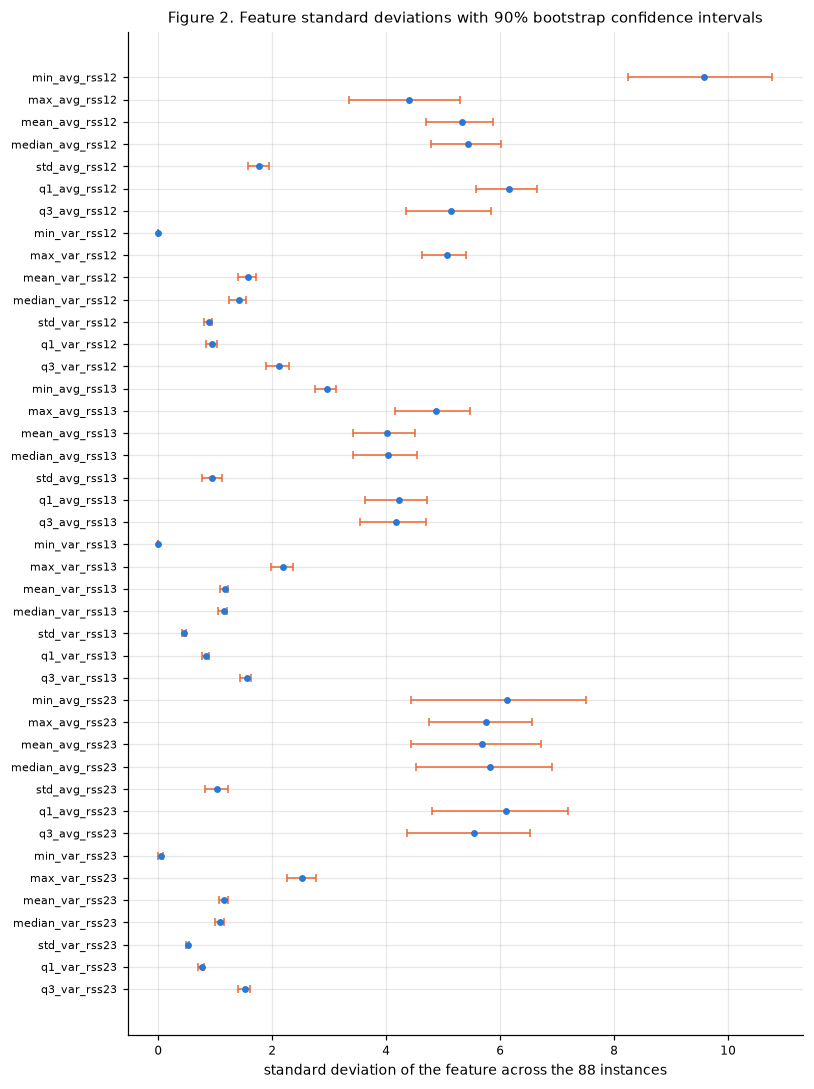

features with zero variance across all 88 instances: ['min_var_rss12', 'min_var_rss13']


In [8]:
# Figure 2: every feature's standard deviation with its 90% bootstrap interval.
fig, ax = plt.subplots(figsize=(7.5, 10))
order = np.arange(len(ci))
ax.errorbar(ci["std"], order,
            xerr=np.vstack([ci["std"] - ci["ci90_low"], ci["ci90_high"] - ci["std"]]),
            fmt="o", ms=3.5, lw=1, capsize=2.5, color=BLUE, ecolor=ORANGE)
ax.set_yticks(order)
ax.set_yticklabels(ci.index, fontsize=7)
ax.invert_yaxis()
ax.set_xlabel("standard deviation of the feature across the 88 instances")
ax.set_title("Figure 2. Feature standard deviations with 90% bootstrap confidence intervals")
fig.tight_layout()
plt.show()

degenerate = ci.index[ci["std"] == 0].tolist()
print("features with zero variance across all 88 instances:", degenerate)

Three things stand out.

1. **Two features are constant.** `min_var_rss12` and `min_var_rss13` are exactly 0 for every
   one of the 88 instances — over a two-minute window, the RSS variance of those two sensor
   pairs always touches zero at least once. Their standard deviation is 0 and the bootstrap
   interval collapses to $[0, 0]$. They carry no information and any model that standardises
   its inputs will simply ignore them. (`min_var_rss23` is nearly degenerate for the same
   reason, with a standard deviation of only 0.046.)
2. **The `avg_*` features vary far more than the `var_*` features.** The largest spread belongs
   to `min_avg_rss12` (std $\approx 9.6$) and the other `avg_rss` location statistics, because
   the mean RSS level differs strongly between activities. This is a first hint that the
   `avg_*` channels carry most of the class signal.
3. **The intervals are tight, and tightest for the stable statistics.** The interval width is a
   median of 22% of the point estimate (10th-90th percentile: 13%-40%). The ten widest intervals
   in absolute terms all belong to the three `avg_rss` channels, simply because those features
   have the largest spread to begin with; the widest of all is `min_avg_rss23` at 3.07, half of
   its own standard deviation. Measured *relative* to each feature's own standard deviation the
   pattern is cleaner and matches theory: `min_*` is by far the least stable statistic (median
   relative width 0.38), `max_*` comes next (0.24), while `mean`, `median`, `std` and the two
   quartiles are all estimated tightly and almost equally well (0.19-0.23). Minima and maxima are
   extreme order statistics that hinge on a single sample, so they move the most under
   resampling.

#### iv. Select Features

"Most important" is judged here by how well a feature separates the classes, measured three
ways: the ANOVA $F$-statistic for the 7-class problem, the $F$-statistic for the binary
*bending vs. other* problem that Homework 4 starts from, and the mutual information with the
7-class label. Each of the seven statistics is scored by averaging over the six series it is
computed from.

Scores are computed on the **training instances only**, so the test set plays no part in
choosing features.

In [9]:
train_mask = ~is_test
X_tr = X_all[train_mask]
y_tr = labels[train_mask]
y_tr_bin = np.where(np.char.startswith(y_tr.astype(str), "bending"), 1, 0)

scores = pd.DataFrame({
    "F_7class": f_classif(X_tr, y_tr)[0],
    "F_binary": f_classif(X_tr, y_tr_bin)[0],
    "MI_7class": mutual_info_classif(X_tr, y_tr, random_state=RANDOM_STATE),
}, index=feature_names).fillna(0.0)
scores["statistic"] = [n.split("_")[0] for n in feature_names]

by_stat = scores.groupby("statistic")[["F_7class", "F_binary", "MI_7class"]].mean()
for c in by_stat.columns:
    by_stat[f"rank_{c}"] = by_stat[c].rank(ascending=False)
by_stat["mean_rank"] = by_stat[[c for c in by_stat.columns if c.startswith("rank_")]].mean(axis=1)
by_stat = by_stat.sort_values("mean_rank")
by_stat.round(3)

,F_7class,F_binary,MI_7class,rank_F_7class,rank_F_binary,rank_MI_7class,mean_rank
statistic,,,,,,,
mean,368.304,10.568,0.931,1.0,2.0,1.0,1.333
q3,350.436,10.312,0.868,2.0,3.0,4.0,3.000
median,317.745,9.435,0.876,3.0,4.0,3.0,3.333
q1,154.115,9.247,0.908,4.0,5.0,2.0,3.667
max,30.030,18.127,0.779,6.0,1.0,6.0,4.333
std,109.179,3.454,0.822,5.0,7.0,5.0,5.667
min,9.759,5.726,0.355,7.0,6.0,7.0,6.667


The univariate scores alone are not enough, because the location statistics (`mean`, `median`,
`q1`, `q3`) are almost perfectly collinear with one another — picking the top three would pick
three copies of the same information. So we also compare every one of the $\binom{7}{3} = 35$
triples directly, by the 5-fold cross-validated accuracy of a plain logistic regression that
uses only the 18 features ($3$ statistics $\times\ 6$ series) of that triple, on the
training set.

In [10]:
cv = StratifiedKFold(5, shuffle=True, random_state=1)


def triple_score(triple):
    cols = [i for i, n in enumerate(feature_names) if n.split("_")[0] in triple]
    pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
    multi = cross_val_score(pipe, X_tr[:, cols], y_tr, cv=cv)
    binary = cross_val_score(pipe, X_tr[:, cols], y_tr_bin, cv=cv)
    return multi.mean(), binary.mean(), multi.std(ddof=1) / np.sqrt(5)


rows = []
for triple in itertools.combinations(STATS, 3):
    m, b, se = triple_score(triple)
    rows.append({"triple": " + ".join(triple), "cv_7class": m, "cv_binary": b,
                 "mean": (m + b) / 2, "se_7class": se})
triples = pd.DataFrame(rows).sort_values("mean", ascending=False).reset_index(drop=True)
triples.index += 1

chosen = "min + max + mean"
rank_of_choice = int(triples.index[triples["triple"] == chosen][0])
best, best_se = triples.loc[1, "mean"], triples.loc[1, "se_7class"]
n_tied = int((triples["mean"] >= best - best_se).sum())
print(f"'{chosen}' ranks {rank_of_choice} of {len(triples)}; "
      f"best = {best:.4f}, chosen = {triples.loc[rank_of_choice, 'mean']:.4f}, "
      f"gap = {best - triples.loc[rank_of_choice, 'mean']:.4f}")
print(f"standard error of the best estimate = {best_se:.4f}; "
      f"{n_tied} of {len(triples)} triples lie within one standard error of the best\n")
pd.concat([triples.head(8), triples.tail(3)]).round(4)

'min + max + mean' ranks 10 of 35; best = 0.9357, chosen = 0.9280, gap = 0.0077
standard error of the best estimate = 0.0484; 32 of 35 triples lie within one standard error of the best



,triple,cv_7class,cv_binary,mean,se_7class
1,max + std + q3,0.9000,0.9714,0.9357,0.0484
2,max + mean + q3,0.9000,0.9714,0.9357,0.0364
3,max + mean + std,0.9000,0.9714,0.9357,0.0484
4,mean + median + std,0.9429,0.9286,0.9357,0.0416
5,max + q1 + q3,0.8989,0.9714,0.9352,0.0362
6,max + std + q1,0.8989,0.9714,0.9352,0.0362
7,max + median + q3,0.8857,0.9714,0.9286,0.0429
8,median + std + q1,0.9286,0.9286,0.9286,0.0391
33,min + median + q1,0.8286,0.9429,0.8857,0.0535
34,mean + median + q1,0.8418,0.9286,0.8852,0.0411


**Selected features: minimum, mean and maximum.**

The justification is that **the ranking is a statistical tie almost all the way down**. The
best triple scores 0.9357 and `min + max + mean` scores 0.9280 — a difference of 0.0077, which
on 69 training instances is *half of one misclassified instance*. The standard error of the
cross-validation estimate is about 0.048, six times that gap, and **32 of the 35 triples fall
within one standard error of the best**. With only 69 training instances the data simply cannot
rank these candidates, so the choice has to be made on grounds other than the leaderboard.
Among the tied group, `min`, `mean` and `max` is the best choice for three reasons:

- **It is not redundant.** `mean`, `median`, `q1` and `q3` are four measurements of the same
  thing; the triples that score marginally higher mostly combine two of them. Taking the two
  extremes plus the centre spans the *range* of each series, so the triple encodes both the
  level and the spread of the signal — `max − min` is recoverable from it, while
  `mean + median + q3` carries essentially one number three times.
- **It is cheap and interpretable.** All three are $O(n)$, need no sorting, and have a direct
  physical reading: the quietest moment, the loudest moment and the average level of a
  sensor pair over the two-minute window.
- **It is robust across both tasks.** It is in the top group for the binary problem
  (0.9714, tied with the best) as well as the 7-class problem.

The one caveat is the degeneracy found in part (iii): `min_var_rss12` and `min_var_rss13` are
constant, so of the 18 features this triple produces, 16 are informative. That costs nothing —
constant columns vanish under standardisation.

These three statistics are the ones carried forward into Homework 4, where the scatter plots
of question 2(a) use them on time series 1, 2 and 6.

## 2. ISLR 3.7.4

> I collect a set of data ($n = 100$ observations) containing a single predictor and a
> quantitative response. I then fit a linear regression model to the data, as well as a
> separate cubic regression, i.e. $Y = \beta_0 + \beta_1 X + \beta_2 X^2 + \beta_3 X^3 + \epsilon$.

Write $\mathrm{RSS}_{\text{lin}}$ and $\mathrm{RSS}_{\text{cub}}$ for the two residual sums of
squares. The key structural fact used throughout is that **the linear model is nested inside
the cubic model**: setting $\beta_2 = \beta_3 = 0$ turns the cubic into the linear fit.

### (a) Linear Train

**The cubic model's training RSS is lower than (at worst equal to) the linear model's, even
though the true relationship is linear.**

Least squares chooses the coefficients that *minimise* the training RSS over the model's
parameter space. The cubic model's parameter space contains the linear model's as the subset
$\{\beta_2 = \beta_3 = 0\}$. Minimising over a larger set cannot produce a larger minimum, so

$$\mathrm{RSS}^{\text{train}}_{\text{cub}} \;\le\; \mathrm{RSS}^{\text{train}}_{\text{lin}}$$

always, whatever the truth is. In practice the inequality is strict: the extra two degrees of
freedom are used to chase the particular noise realisation in the 100 training points, so the
cubic fit will track the sample a little more closely. This is pure overfitting and tells us
nothing good about the cubic model — it is why training RSS must never be used to compare
models of different flexibility.

### (b) Linear Test

**The linear model's test RSS is expected to be lower.**

Expected test error decomposes as $\text{bias}^2 + \text{variance} + \sigma^2$. Because the
true relationship *is* linear, the linear model is correctly specified and has **zero bias**.
The cubic model also has zero bias — it contains the truth — so neither model wins on bias.
They differ only in variance: the cubic estimates 4 coefficients from 100 points instead of 2,
so its fitted function is more sensitive to the training noise and its variance is strictly
larger. Adding variance with no bias reduction can only raise expected test error, hence

$$\mathbb{E}\left[\mathrm{RSS}^{\text{test}}_{\text{lin}}\right] \;<\;
  \mathbb{E}\left[\mathrm{RSS}^{\text{test}}_{\text{cub}}\right].$$

This is an expectation, not a guarantee: on one particular finite test set the cubic model can
get lucky and score lower. Over repeated samples the linear model wins.

### (c) Not Linear Train

**The cubic model's training RSS is still lower, and we do not need to know how non-linear the
truth is to say so.**

The nesting argument of part (a) is purely algebraic — it never referred to the true
relationship. Whatever generated the data, least squares minimising over 4 parameters cannot do
worse on the training set than least squares minimising over 2 of them:

$$\mathrm{RSS}^{\text{train}}_{\text{cub}} \;\le\; \mathrm{RSS}^{\text{train}}_{\text{lin}}.$$

Here the gap has two sources rather than one: the cubic terms absorb genuine curvature *and*
some noise, so the reduction will typically be larger than in part (a).

### (d) Not Linear Testing

**There is not enough information to tell.** This is the one case where the answer is genuinely
indeterminate, and the reason is the bias-variance trade-off.

Moving from the linear to the cubic model always *adds variance* (4 parameters instead of 2)
and *removes bias* (the cubic can represent curvature the line cannot). Which effect dominates
depends on how far from linear the truth is — which the question explicitly says we do not know:

- If the truth is only **mildly** curved, the bias the line suffers is small, the extra variance
  dominates, and the **linear** model has lower test RSS.
- If the truth is **strongly** curved (and well approximated by a cubic), the bias reduction
  dominates and the **cubic** model has lower test RSS.
- If the truth is curved but *not* cubic — say $Y = \sin(X)$ over a wide range, or a sharp
  kink — both models are biased and either can win, depending also on $\sigma^2$ and $n$.

The simulation below makes this concrete: the same two models are fitted to data generated with
an increasing amount of curvature, and the test RSS of the linear and cubic fits cross over.

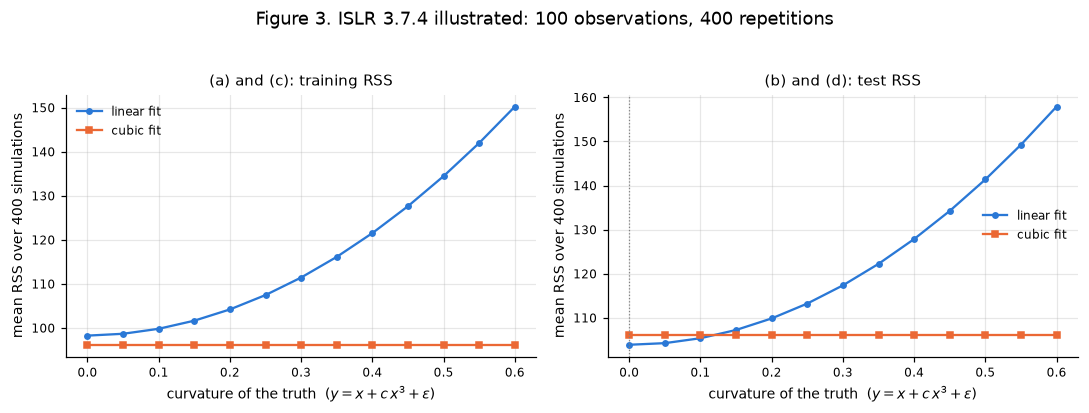

training RSS: cubic below linear at every curvature  -> True
test RSS at c = 0 (truth is linear): linear 103.9 vs cubic 106.1
the cubic fit first wins on test RSS at curvature c = 0.15


In [11]:
def simulate(curvature, n=100, sigma=1.0, n_rep=400, rng=None):
    """Average train/test RSS of a linear and a cubic fit when y = x + curvature*x^3 + noise."""
    rng = rng or np.random.default_rng(RANDOM_STATE)
    out = np.zeros((n_rep, 4))
    for r in range(n_rep):
        x = rng.uniform(-2, 2, n)
        f = x + curvature * x ** 3
        y = f + rng.normal(0, sigma, n)
        x_te = rng.uniform(-2, 2, n)
        y_te = x_te + curvature * x_te ** 3 + rng.normal(0, sigma, n)
        for j, deg in enumerate([1, 3]):
            m = make_pipeline(PolynomialFeatures(deg), LinearRegression())
            m.fit(x[:, None], y)
            out[r, j] = np.sum((y - m.predict(x[:, None])) ** 2)
            out[r, j + 2] = np.sum((y_te - m.predict(x_te[:, None])) ** 2)
    return out.mean(axis=0)


curvatures = np.linspace(0, 0.6, 13)
sim = pd.DataFrame([simulate(c) for c in curvatures],
                   columns=["train_linear", "train_cubic", "test_linear", "test_cubic"])
sim.insert(0, "curvature", curvatures)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, kind, title in zip(axes, ["train", "test"],
                           ["(a) and (c): training RSS", "(b) and (d): test RSS"]):
    ax.plot(sim["curvature"], sim[f"{kind}_linear"], "o-", ms=3.5, color=BLUE, label="linear fit")
    ax.plot(sim["curvature"], sim[f"{kind}_cubic"], "s-", ms=3.5, color=ORANGE, label="cubic fit")
    ax.set_xlabel(r"curvature of the truth  ($y = x + c\,x^3 + \epsilon$)")
    ax.set_ylabel("mean RSS over 400 simulations")
    ax.set_title(title)
    ax.legend(frameon=False)
axes[1].axvline(0, color="grey", lw=0.8, ls=":")
fig.suptitle("Figure 3. ISLR 3.7.4 illustrated: 100 observations, 400 repetitions", y=1.03)
fig.tight_layout()
plt.show()

cross = sim.loc[sim["test_cubic"] < sim["test_linear"], "curvature"]
print(f"training RSS: cubic below linear at every curvature  -> "
      f"{bool((sim['train_cubic'] <= sim['train_linear']).all())}")
print(f"test RSS at c = 0 (truth is linear): linear {sim.loc[0, 'test_linear']:.1f} "
      f"vs cubic {sim.loc[0, 'test_cubic']:.1f}")
print(f"the cubic fit first wins on test RSS at curvature c = {cross.iloc[0]:.2f}")

The simulation confirms all four answers. The cubic training RSS (orange, left panel) is below
the linear one at every curvature, including $c = 0$ where the truth is exactly linear —
parts (a) and (c). On test data the ordering flips with $c$: at $c = 0$ the linear fit wins
(test RSS 103.9 against 106.1), which is part (b), and the two curves cross at about
$c = 0.15$, beyond which the cubic fit wins. That crossover is exactly why part (d) cannot be
answered without knowing how far from linear the truth is: the answer depends on which side of
it the data generating process happens to lie.

## 3.1. ISLR 3.7.3 — Extra Practice

> Suppose we have a data set with five predictors, $X_1 = \text{GPA}$, $X_2 = \text{IQ}$,
> $X_3 = \text{Level}$ (1 for College and 0 for High School), $X_4 = \text{GPA} \times \text{IQ}$,
> and $X_5 = \text{GPA} \times \text{Level}$. The response is starting salary after graduation
> (in thousands of dollars). Suppose we use least squares to fit the model, and get
> $\hat\beta_0 = 50$, $\hat\beta_1 = 20$, $\hat\beta_2 = 0.07$, $\hat\beta_3 = 35$,
> $\hat\beta_4 = 0.01$, $\hat\beta_5 = -10$.

**(a) Which answer is correct, and why?**

The fitted model is

$$\widehat{\text{Salary}} = 50 + 20\,\text{GPA} + 0.07\,\text{IQ} + 35\,\text{Level}
  + 0.01\,(\text{GPA} \times \text{IQ}) - 10\,(\text{GPA} \times \text{Level}).$$

Hold GPA and IQ fixed and take the difference between a college graduate
($\text{Level} = 1$) and a high school graduate ($\text{Level} = 0$). Every term without
`Level` cancels:

$$\widehat{\text{Salary}}_{\text{college}} - \widehat{\text{Salary}}_{\text{HS}}
  = 35 - 10\,\text{GPA}.$$

This is positive when $\text{GPA} < 3.5$ and negative when $\text{GPA} > 3.5$. So college
graduates earn more at low GPA, and high school graduates earn more once GPA exceeds 3.5.

**Answer: iii** — *for a fixed value of IQ and GPA, high school graduates earn more, on
average, than college graduates provided that the GPA is high enough.*

Options i and ii are both wrong because they claim an unconditional ordering, while the sign of
the difference depends on GPA through the $\text{GPA} \times \text{Level}$ interaction. Option
iv has the inequality the wrong way round.

**(b) Predict the salary of a college graduate with IQ of 110 and a GPA of 4.0.**

$$\begin{aligned}
\widehat{\text{Salary}} &= 50 + 20(4.0) + 0.07(110) + 35(1) + 0.01(4.0 \times 110) - 10(4.0 \times 1)\\
 &= 50 + 80 + 7.7 + 35 + 4.4 - 40 \\
 &= 137.1
\end{aligned}$$

The predicted starting salary is **137.1 thousand dollars** (\$137,100).

In [12]:
gpa, iq, level = 4.0, 110, 1
beta = [50, 20, 0.07, 35, 0.01, -10]
salary = (beta[0] + beta[1] * gpa + beta[2] * iq + beta[3] * level
          + beta[4] * gpa * iq + beta[5] * gpa * level)
print(f"predicted salary = {salary:.1f} thousand dollars")

# Where does the college/high-school advantage flip sign?
print(f"college premium = 35 - 10*GPA, which is zero at GPA = {35 / 10:.1f}")

predicted salary = 137.1 thousand dollars
college premium = 35 - 10*GPA, which is zero at GPA = 3.5


**(c) True or false: since the coefficient for the GPA/IQ interaction term is very small, there
is very little evidence of an interaction effect.**

**False.** The claim confuses the *magnitude* of a coefficient with the *evidence* for it.

1. **A coefficient's size depends on the units of its predictor.** $\text{GPA} \times \text{IQ}$
   runs from about 0 to $4 \times 130 = 520$, so $\hat\beta_4 = 0.01$ contributes up to
   $0.01 \times 520 \approx 5.2$ thousand dollars — the same order of magnitude as the other
   effects in the model, and hardly negligible. Rescaling IQ to, say, hundreds of points would
   multiply $\hat\beta_4$ by 100 without changing the model's fit at all.
2. **Evidence is about the coefficient relative to its uncertainty.** The relevant quantity is
   the $t$-statistic $\hat\beta_4 / \mathrm{SE}(\hat\beta_4)$ and its $p$-value, or equivalently
   a confidence interval for $\beta_4$. A small $\hat\beta_4$ with a much smaller standard error
   is strong evidence of an interaction; a large $\hat\beta_4$ with a huge standard error is not.
   The question gives no standard errors, so **no conclusion about significance can be drawn
   from the information provided**.

## 3.2. ISLR 3.7.5 — Extra Practice

> Consider the fitted values that result from performing linear regression without an
> intercept. In this setting, the $i$th fitted value takes the form
> $\hat{y}_i = x_i \hat\beta$, where
> $\hat\beta = \left(\sum_{i=1}^n x_i y_i\right) \big/ \left(\sum_{i'=1}^n x_{i'}^2\right)$.
> Show that we can write $\hat{y}_i = \sum_{i'=1}^n a_{i'} y_{i'}$. What is $a_{i'}$?

Substitute $\hat\beta$ into $\hat{y}_i = x_i \hat\beta$ and rename the summation index in the
numerator to $i'$ (it is a bound variable, so this is free):

$$\hat{y}_i \;=\; x_i\,\hat\beta
  \;=\; x_i \cdot \frac{\displaystyle\sum_{i'=1}^{n} x_{i'} y_{i'}}{\displaystyle\sum_{k=1}^{n} x_k^2}.$$

The denominator does not depend on $i'$, so both it and the factor $x_i$ can be moved inside
the sum:

$$\hat{y}_i \;=\; \sum_{i'=1}^{n} \frac{x_i\, x_{i'}}{\displaystyle\sum_{k=1}^{n} x_k^2}\, y_{i'}
           \;=\; \sum_{i'=1}^{n} a_{i'}\, y_{i'},
\qquad\text{with}\qquad
\boxed{\;a_{i'} \;=\; \frac{x_i\, x_{i'}}{\displaystyle\sum_{k=1}^{n} x_k^{2}}\;}$$

**Interpretation.** The fitted value at observation $i$ is a *linear combination of all $n$
observed responses* — the weights $a_{i'}$ do not depend on $y$ at all, only on the predictor
values. This is what it means to call least squares a **linear smoother**. The weight placed on
$y_{i'}$ is proportional to $x_i x_{i'}$: observations whose predictor is large in magnitude
and of the same sign as $x_i$ pull the fitted value up, those of opposite sign pull it down,
and an observation with $x_{i'} = 0$ has no influence whatsoever. Note that $a_{i'}$ depends on
$i$ as well, so strictly it should be written $a_{i i'}$; stacking these gives
$\hat{\mathbf{y}} = H\mathbf{y}$ with the hat matrix $H = \mathbf{x}\mathbf{x}^\top / \|\mathbf{x}\|^2$.

In [13]:
# Numerical check of the identity on random data.
rng = np.random.default_rng(RANDOM_STATE)
x = rng.normal(size=12)
y = rng.normal(size=12)
beta_hat = (x * y).sum() / (x ** 2).sum()
y_hat_direct = x * beta_hat
A = np.outer(x, x) / (x ** 2).sum()      # A[i, i'] = x_i x_i' / sum_k x_k^2
y_hat_weights = A @ y
print("max |difference| between the two expressions:",
      f"{np.abs(y_hat_direct - y_hat_weights).max():.2e}")
print("weights for i = 0 sum to:", f"{A[0].sum():.4f}  (they need not sum to 1)")

max |difference| between the two expressions: 4.16e-17
weights for i = 0 sum to: -0.0500  (they need not sum to 1)


## References

- Palumbo, F., Gallicchio, C., Pucci, R., Micheli, A. (2016). *Human activity recognition using
  multisensor data fusion based on Reservoir Computing.* Journal of Ambient Intelligence and
  Smart Environments. — the source of the AReM data set.
- UCI Machine Learning Repository: [Activity Recognition system based on Multisensor data fusion (AReM)](https://archive.ics.uci.edu/ml/datasets/Activity+Recognition+system+based+on+Multisensor+data+fusion+%28AReM%29)
- James, G., Witten, D., Hastie, T., Tibshirani, R. *An Introduction to Statistical Learning*,
  2nd ed. — Sections 2.2 (bias-variance trade-off), 3.3 (interactions, the hierarchy
  principle) and exercises 3.7.3, 3.7.4, 3.7.5.
- Efron, B., Tibshirani, R. (1993). *An Introduction to the Bootstrap*, Chapman & Hall. —
  the percentile bootstrap interval used in 1(c)iii.
- Figo, D., Diniz, P. C., Ferreira, D. R., Cardoso, J. M. P. (2010).
  *Preprocessing techniques for context recognition from accelerometer data.*
  Personal and Ubiquitous Computing, 14(7), 645-662. — survey of the time-domain features
  listed in 1(c)i.
- scikit-learn documentation: [`f_classif`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.f_classif.html),
  [`mutual_info_classif`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.mutual_info_classif.html),
  [`StratifiedKFold`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html)